# Notebook 06 · Entrenamiento del modelo de latidos

**Módulo de latidos**

Aquí ahora si ya se alimenta la red que diseñé en el notebook 05, el cual no tenía inpiuts, con latidos reales de MIT-BIH Arrhythmia, para que aprenda a distinguir latidos N (normales), S (supraventriculares) y V (ventriculares).

```
Pasos:
1. Descargar MIT-BIH Arrhythmia
2. Recortar y normalizar cada latido (234 puntos)
3. Separar por paciente: entrenamiento (DS1) · validación (pacientes de DS1 apartados) · prueba (DS2)
4. Equilibrar las clases (por que hay muchos más N que S o V)
5. Entrenar con early stopping para que no haya sobreajustes y revisar las curvas de aprendizaje
6. Evaluar UNA vez en la prueba (DS2) y comparar contra un kNN (la línea base)
7. Cuantizar a INT8, volver a evaluar y guardar el modelo para que quede para el Arduino
```

In [1]:
%pip install -q wfdb

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb
from IPython.display import display
from scipy.signal import butter, sosfilt
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_class_weight

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True

EN_KAGGLE = Path("/kaggle/input").exists()
SALIDA = Path("/kaggle/working") if EN_KAGGLE else Path(".")
DATOS = SALIDA / "datos"
DATOS.mkdir(parents=True, exist_ok=True)

## 1. Decisiones del entrenamiento


| Decisión | Valor | Por qué |
|---|---|---|
| Clases | N, S, V (AAMI) | Estándar en la literatura; S (supraventricular) se incluye para que el modelo no la confunda con V (ventricular) |
| Latidos Q | Se quitaron, igual que los 4 registros con marcapasos  | Son de marcapasos o no clasificables (práctica estándar) |
| Latidos F (fusión) | Se quitan | Son una mezcla de latido normal y ventricular (ambiguos) y muy pocos (~800) para ser una clase propia |
| Entrada | Solo la forma del latido: 0.25 s antes y 0.40 s después del pico R (234 puntos) | Primer modelo, simple. Los R–R se pueden agregar después |
| Entrenamiento / prueba | DS1 / DS2 (de literatura Chazal et al., 2004) | División estándar entre pacientes: sin fuga de datos |
| Validación | 4 pacientes de DS1 apartados completos | Para decidir cuándo parar sin tocar la prueba |
| Desbalance | Pesos por clase (*class weights*) | Equivocarse en un S o un V nos cuesta más que en un N |

In [3]:
FS = 360
ANTES_S, DESPUES_S = 0.25, 0.40
LARGO = int(ANTES_S * FS) + int(DESPUES_S * FS)        # 234 puntos
CLASES = ["N", "S", "V"]
QUE_HACER_CON_F = "quitar"                             # opciones: "quitar" o "juntar_con_V"

# Agrupación AAMI de los símbolos de MIT-BIH
AAMI = {"N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
        "A": "S", "a": "S", "J": "S", "S": "S",
        "V": "V", "E": "V",
        "F": "F",
        "/": "Q", "f": "Q", "Q": "Q"}

DS1 = ["101", "106", "108", "109", "112", "114", "115", "116", "118", "119", "122",
       "124", "201", "203", "205", "207", "208", "209", "215", "220", "223", "230"]
DS2 = ["100", "103", "105", "111", "113", "117", "121", "123", "200", "202", "210",
       "212", "213", "214", "219", "221", "222", "228", "231", "232", "233", "234"]
N_PACIENTES_VALIDACION = 4

SEMILLA = 42
EPOCAS_MAX = 100         # máximo de vueltas; early stopping suele parar antes
TAMANO_LOTE = 256        # latidos que ve la red antes de cada ajuste
PACIENCIA = 15           # épocas sin mejorar el F1 macro de validación antes de parar
TASA_APRENDIZAJE = 1e-3

# Arquitectura (la misma del notebook 05)
FILTROS_1, KERNEL_1 = 8, 7
FILTROS_2, KERNEL_2 = 16, 5
FILTROS_3, KERNEL_3 = 32, 5
POOL = 2

---
## 2. Descargar MIT-BIH Arrhythmia

Se bajan solo los 44 registros que se usan (DS1 + DS2), ~100 MB. Si PhysioNet falla, la celda reintenta sola. Si ya están descargados, no los vuelve a bajar.

In [4]:
REGISTROS = DS1 + DS2
hea = next(Path("/kaggle/input").rglob("208.hea"), None) if EN_KAGGLE else None
CARPETA = hea.parent if hea else DATOS / "mitdb"

def faltantes():
    return [r for r in REGISTROS if not all((CARPETA / f"{r}.{e}").exists() for e in ("hea", "dat", "atr"))]

for r in faltantes():
    for intento in range(1, 6):
        try:
            wfdb.dl_database("mitdb", str(CARPETA), records=[r])
            break
        except Exception as e:
            print(f"  {r}: PhysioNet falló ({type(e).__name__}). Reintento {intento}/5 en 30 s...")
            time.sleep(30)
if faltantes():
    raise RuntimeError(f"Faltan {faltantes()}: vuelve a correr esta celda más tarde")
print(f"✓ MIT-BIH Arrhythmia lista en {CARPETA} ({len(REGISTROS)} registros)")

Generating record list for: 101
Generating list of all files for: 101
Created local base download directory: /kaggle/working/datos/mitdb
Finished downloading files
Generating record list for: 106
Generating list of all files for: 106
Finished downloading files
Generating record list for: 108
Generating list of all files for: 108
Finished downloading files
Generating record list for: 109
Generating list of all files for: 109
Finished downloading files
Generating record list for: 112
Generating list of all files for: 112
Finished downloading files
Generating record list for: 114
Generating list of all files for: 114
Finished downloading files
Generating record list for: 115
Generating list of all files for: 115
Finished downloading files
Generating record list for: 116
Generating list of all files for: 116
Finished downloading files
Generating record list for: 118
Generating list of all files for: 118
Finished downloading files
Generating record list for: 119
Generating list of all files

---
## 3. Recortar y normalizar cada latido

Para cada registro:
1. Se lee la derivación **MLII** (la más parecida a la del AD8232).
2. Se **filtra** con el mismo filtro **causal** de 0.5–40 Hz del notebook 03.
3. Para cada latido anotado, se **recorta** de 0.25 s antes a 0.40 s después de su pico R (234 puntos).
4. Se **normaliza cada latido**: se le resta su promedio y se divide entre su desviación estándar, para que no importe si la señal de un paciente es más grande que la de otro. *(El Arduino hará exactamente lo mismo con cada latido; no necesita guardar ningún número de normalización.)*
5. Se le pone su **clase AAMI**. Los Q y los F se quitan.

> Para entrenar se usan las posiciones de R **anotadas por los cardiólogos**. En el dispositivo se usará nuestro detector; esa diferencia se evaluará después.

In [5]:
SOS = butter(2, [0.5, 40.0], btype="bandpass", fs=FS, output="sos")
a, b = int(ANTES_S * FS), int(DESPUES_S * FS)

def latidos_de_registro(nombre):
    ruta = str(CARPETA / nombre)
    canales = wfdb.rdheader(ruta).sig_name
    canal = canales.index("MLII") if "MLII" in canales else 0
    x = wfdb.rdrecord(ruta, channels=[canal]).p_signal[:, 0]
    limpia = sosfilt(SOS, x)
    ann = wfdb.rdann(ruta, "atr")
    X, y = [], []
    for pos, sim in zip(ann.sample, ann.symbol):
        clase = AAMI.get(sim)
        if clase is None or clase == "Q":
            continue                                   # no es latido, o es de marcapasos / no clasificable
        if clase == "F":
            if QUE_HACER_CON_F == "quitar":
                continue
            clase = "V"
        if pos - a < 0 or pos + b > len(limpia):
            continue                                   # latido incompleto al inicio o al final
        trozo = limpia[pos - a: pos + b]
        X.append((trozo - trozo.mean()) / (trozo.std() + 1e-6))
        y.append(CLASES.index(clase))
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

datos = {}
for r in REGISTROS:
    datos[r] = latidos_de_registro(r)
conteo = pd.DataFrame({r: np.bincount(datos[r][1], minlength=3) for r in REGISTROS}, index=CLASES).T
conteo["conjunto"] = ["DS1" if r in DS1 else "DS2" for r in conteo.index]
display(conteo.groupby("conjunto")[CLASES].sum())

,N,S,V
conjunto,,,
DS1,45849,944,3788
DS2,44240,1837,3220


**Cómo leerlo:** cuántos latidos de cada clase hay en DS1 y en DS2. Fíjate en el **desbalance**: la gran mayoría son N.

## 4. Separar por paciente: entrenamiento, validación y prueba

- **Prueba = DS2** (22 pacientes): no se toca hasta el final.
- **Validación = 4 pacientes de DS1**, apartados **completos**. Se sortean (con semilla fija) hasta que la validación y el entrenamiento tengan latidos S y V suficientes.
- **Entrenamiento = el resto de DS1.**

> Nota conocida de esta división: los registros 201 (DS1) y 202 (DS2) son del mismo paciente. Se mantiene así para poder comparar con la literatura, que usa la misma división, y se documenta como limitación.

In [6]:
rng = np.random.default_rng(SEMILLA)
for intento in range(1, 1001):
    val = [str(r) for r in rng.choice(DS1, size=N_PACIENTES_VALIDACION, replace=False)]
    ent = [r for r in DS1 if r not in val]
    c_val, c_ent = conteo.loc[val, CLASES].sum(), conteo.loc[ent, CLASES].sum()
    if c_val["S"] >= 50 and c_val["V"] >= 50 and c_ent["S"] >= 200 and c_ent["V"] >= 200:
        break
print(f"Sorteo aceptado en el intento {intento}")
print("Validación:   ", sorted(val))
print("Entrenamiento:", sorted(ent))

def juntar(registros):
    X = np.concatenate([datos[r][0] for r in registros])[..., None]   # forma (latidos, 234, 1)
    y = np.concatenate([datos[r][1] for r in registros])
    return X, y

X_ent, y_ent = juntar(ent)
X_val, y_val = juntar(val)
X_pru, y_pru = juntar(DS2)
assert not (set(ent) & set(val)) and not (set(ent) & set(DS2)) and not (set(val) & set(DS2))
print("✓ Ningún paciente está en dos conjuntos")
resumen = pd.DataFrame({n: np.bincount(y, minlength=3) for n, y in
                        [("entrenamiento", y_ent), ("validación", y_val), ("prueba (DS2)", y_pru)]}, index=CLASES).T
resumen["total"] = resumen.sum(axis=1)
display(resumen)

Sorteo aceptado en el intento 1
Validación:    ['106', '119', '203', '207']
Entrenamiento: ['101', '108', '109', '112', '114', '115', '116', '118', '122', '124', '201', '205', '208', '209', '215', '220', '223', '230']
✓ Ningún paciente está en dos conjuntos


,N,S,V,total
entrenamiento,38728,835,2170,41733
validación,7121,109,1618,8848
prueba (DS2),44240,1837,3220,49297


### 4.1 ¿Cómo se ve un latido de cada clase? (promedio del entrenamiento)

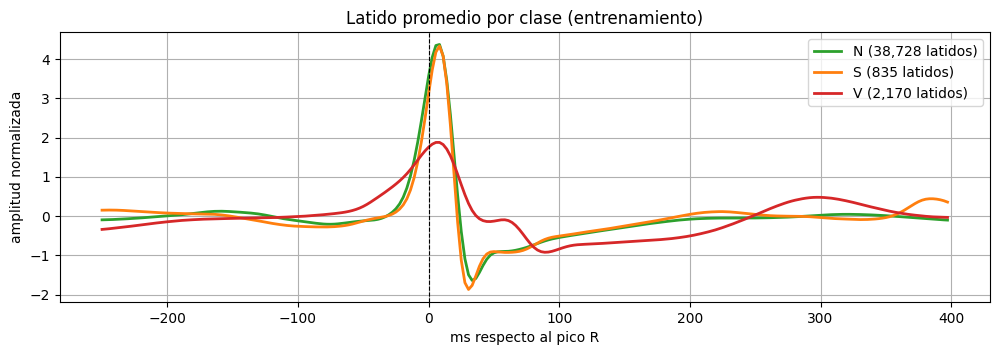

In [7]:
t_ms = 1000 * (np.arange(LARGO) - a) / FS
for i, (clase, color) in enumerate(zip(CLASES, ["tab:green", "tab:orange", "tab:red"])):
    plt.plot(t_ms, X_ent[y_ent == i, :, 0].mean(axis=0), color=color, lw=2,
             label=f"{clase} ({(y_ent == i).sum():,} latidos)")
plt.axvline(0, color="k", ls="--", lw=0.8)
plt.xlabel("ms respecto al pico R"); plt.ylabel("amplitud normalizada"); plt.legend()
plt.title("Latido promedio por clase (entrenamiento)"); plt.show()

## 5. Equilibrar las clases con pesos

Si a la red le da igual equivocarse en cualquier latido, aprende a decir **siempre N** (acertaría ~90 % sin aprender nada). Los **pesos por clase** hacen que equivocarse en una clase rara cueste más: cada clase pesa en proporción inversa a cuántos latidos tiene.

In [8]:
pesos = compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y_ent)
PESOS = {i: float(p) for i, p in enumerate(pesos)}
display(pd.DataFrame({"latidos": np.bincount(y_ent, minlength=3), "peso": pesos.round(2)}, index=CLASES))

,latidos,peso
N,38728,0.36
S,835,16.66
V,2170,6.41


---
## 6. Construir y "compilar" el modelo

Es la **misma arquitectura del notebook 05** (5 capas, ~971 parámetros). **Compilar** = decirle **cómo** va a aprender:

- **Pérdida** (`sparse_categorical_crossentropy`): mide **qué tan equivocada** está la red en cada latido. Entrenar = bajar este número.
- **Optimizador** (`Adam`): el que **ajusta los 971 parámetros** un poquito después de cada lote, en la dirección que baja la pérdida.
- **Métrica** (`accuracy`): solo para ver el avance. La evaluación seria se hace después, con sensibilidad, especificidad y F1.

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEMILLA)
keras.utils.set_random_seed(SEMILLA)

modelo = keras.Sequential([
    keras.Input(shape=(LARGO, 1), name="latido"),
    layers.Conv1D(FILTROS_1, KERNEL_1, padding="same", activation="relu", name="c1_conv"),
    layers.MaxPooling1D(POOL, name="c1_pool"),
    layers.SeparableConv1D(FILTROS_2, KERNEL_2, padding="same", activation="relu", name="c2_sepconv"),
    layers.MaxPooling1D(POOL, name="c2_pool"),
    layers.SeparableConv1D(FILTROS_3, KERNEL_3, padding="same", activation="relu", name="c3_sepconv"),
    layers.MaxPooling1D(POOL, name="c3_pool"),
    layers.GlobalAveragePooling1D(name="c4_gap"),
    layers.Dense(len(CLASES), activation="softmax", name="c5_dense"),
], name="ds_cnn_latidos")

modelo.compile(optimizer=keras.optimizers.Adam(TASA_APRENDIZAJE),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "ds_cnn_latidos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ c1_conv (Conv1D)                │ (None, 234, 8)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c1_pool (MaxPooling1D)          │ (None, 117, 8)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c2_sepconv (SeparableConv1D)    │ (None, 117, 16)        │           184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c2_pool (MaxPooling1D)          │ (None, 58, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c3_sepconv (SeparableConv1D)    │ (None, 58, 32)         │           624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c3_pool (MaxPooling1D)          │ (None, 29, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c4_gap (GlobalAveragePooling1D) │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ c5_dense (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 971 (3.79 KB)

 Trainable params: 971 (3.79 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entrenar

La red ve **todos los latidos de entrenamiento** varias veces. Cada vuelta completa es una **época**. En cada época, por cada lote de 256 latidos: adivina, compara con la respuesta correcta y ajusta sus parámetros.

**¿Cuándo parar? (early stopping)** Al final de cada época se mide el **F1 promedio de las 3 clases (F1 macro)** en los pacientes de **validación**. Si no mejora en 15 épocas seguidas, se **detiene** y se queda con los parámetros de la **mejor** época.

> **Por qué F1 macro y no la pérdida ni la exactitud:** la exactitud premia decir "N" a todo (casi todos los latidos son N), y la pérdida de validación sin pesos tampoco toma en cuenta que los S y V nos importan más. El F1 macro le da **el mismo peso a N, S y V**, que es justo lo que queremos. Además, la pérdida de validación se calcula **con los mismos pesos por clase** que la de entrenamiento, para que las dos curvas sean comparables.

In [10]:
w_val = np.array([PESOS[int(c)] for c in y_val], dtype=np.float32)   # mismos pesos que en entrenamiento

class ParaPorF1(keras.callbacks.Callback):
    # Mide el F1 macro en validación al final de cada época, guarda la mejor y para si no mejora.
    def __init__(self, paciencia):
        super().__init__()
        self.paciencia = paciencia
        self.mejor_f1, self.mejor_epoca, self.esperando = -1.0, 0, 0
        self.pesos_mejores, self.f1s = None, []

    def on_epoch_end(self, epoca, logs=None):
        prob = np.concatenate([np.asarray(self.model(X_val[i:i + 2048], training=False))
                               for i in range(0, len(X_val), 2048)])
        f1 = f1_score(y_val, prob.argmax(axis=1), average="macro",
                      labels=list(range(len(CLASES))), zero_division=0)
        self.f1s.append(f1)
        if f1 > self.mejor_f1:
            self.mejor_f1, self.mejor_epoca, self.esperando = f1, epoca + 1, 0
            self.pesos_mejores = self.model.get_weights()
        else:
            self.esperando += 1
            if self.esperando >= self.paciencia:
                self.model.stop_training = True
        print(f"   F1 macro en validación: {f1:.3f}  (mejor hasta ahora: {self.mejor_f1:.3f}, época {self.mejor_epoca})")

    def on_train_end(self, logs=None):
        if self.pesos_mejores is not None:
            self.model.set_weights(self.pesos_mejores)

parar_por_f1 = ParaPorF1(PACIENCIA)
inicio = time.time()
historia = modelo.fit(X_ent, y_ent, validation_data=(X_val, y_val, w_val),
                      epochs=EPOCAS_MAX, batch_size=TAMANO_LOTE,
                      class_weight=PESOS, callbacks=[parar_por_f1], verbose=2)
mejor_epoca = parar_por_f1.mejor_epoca
print(f"\nEntrenamiento terminado en {time.time() - inicio:.0f} s · época conservada: {mejor_epoca} "
      f"de {len(historia.history['loss'])} · F1 macro en validación: {parar_por_f1.mejor_f1:.3f}")

Epoch 1/100
   F1 macro en validación: 0.400  (mejor hasta ahora: 0.400, época 1)
164/164 - 13s - 81ms/step - accuracy: 0.5861 - loss: 1.0323 - val_accuracy: 0.6249 - val_loss: 1.3592
Epoch 2/100
   F1 macro en validación: 0.441  (mejor hasta ahora: 0.441, época 2)
164/164 - 2s - 10ms/step - accuracy: 0.4954 - loss: 0.6868 - val_accuracy: 0.6896 - val_loss: 1.6711
Epoch 3/100
   F1 macro en validación: 0.440  (mejor hasta ahora: 0.441, época 2)
164/164 - 2s - 9ms/step - accuracy: 0.5484 - loss: 0.6341 - val_accuracy: 0.6916 - val_loss: 1.7722
Epoch 4/100
   F1 macro en validación: 0.442  (mejor hasta ahora: 0.442, época 4)
164/164 - 2s - 9ms/step - accuracy: 0.5831 - loss: 0.6161 - val_accuracy: 0.6887 - val_loss: 1.8109
Epoch 5/100
   F1 macro en validación: 0.441  (mejor hasta ahora: 0.442, época 4)
164/164 - 2s - 9ms/step - accuracy: 0.6038 - loss: 0.6012 - val_accuracy: 0.6864 - val_loss: 1.8239
Epoch 6/100
   F1 macro en validación: 0.439  (mejor hasta ahora: 0.442, época 4)
164/1

## 8. Curvas de aprendizaje

- **Pérdida:** si las dos curvas **bajan juntas**, la red aprende algo que sirve también en pacientes nuevos. ✅ Si la de entrenamiento baja y la de validación **sube**, aprende cosas que solo sirven para los pacientes de entrenamiento. ⚠️
- **F1 macro en validación:** es la curva que decide qué época se conserva (línea punteada). Más alto = mejor.

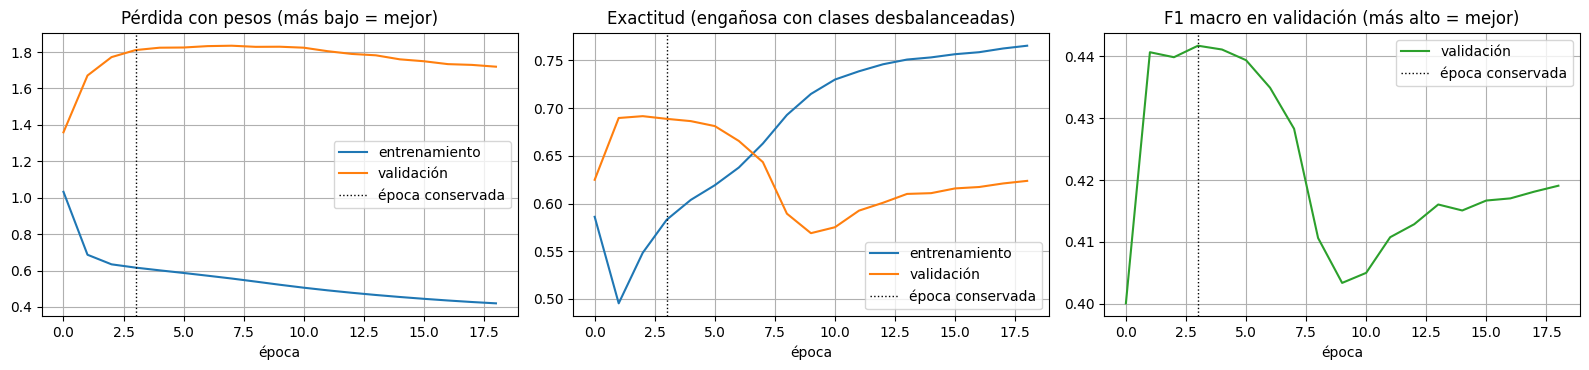

In [11]:
h = historia.history
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(h["loss"], label="entrenamiento"); ax[0].plot(h["val_loss"], label="validación")
ax[0].set_title("Pérdida con pesos (más bajo = mejor)"); ax[0].set_xlabel("época")
ax[1].plot(h["accuracy"], label="entrenamiento"); ax[1].plot(h["val_accuracy"], label="validación")
ax[1].set_title("Exactitud (engañosa con clases desbalanceadas)"); ax[1].set_xlabel("época")
ax[2].plot(parar_por_f1.f1s, color="tab:green", label="validación")
ax[2].set_title("F1 macro en validación (más alto = mejor)"); ax[2].set_xlabel("época")
for eje in ax:
    eje.axvline(mejor_epoca - 1, color="k", ls=":", lw=1, label="época conservada"); eje.legend()
plt.tight_layout(); plt.show()

---
## 9. Evaluar en la prueba (DS2): **una sola vez**

Pacientes que la red **nunca vio**. Medimos por clase, con las métricas de mi hipótesis:

- **Sensibilidad (Se):** de los latidos reales de esa clase, ¿cuántos encontró?
- **Especificidad (Sp):** de los latidos que **no** son de esa clase, ¿cuántos dijo bien que no lo eran?
- **PPV:** cuando dijo esa clase, ¿cuántas veces acertó?
- **F1:** un resumen de Se y PPV.

Meta del proyecto: **Se y Sp ≥ 90 %** (sobre todo para **V**).

--- Red DS-CNN (float32) · DS2 ---


,Se %,Sp %,PPV %,F1
clase,,,,
N,91.43,67.45,96.09,0.94
S,19.00,93.78,10.57,0.14
V,94.22,98.12,77.77,0.85
promedio (macro),68.22,86.45,61.48,0.64


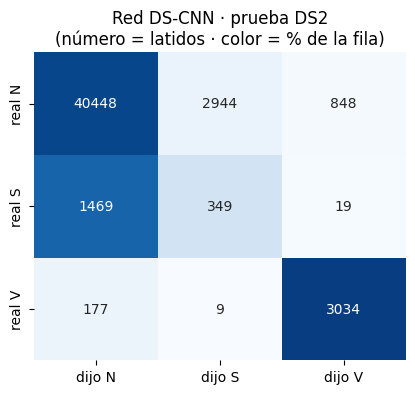

In [12]:
def metricas(y_real, y_pred, nombre):
    cm = confusion_matrix(y_real, y_pred, labels=range(len(CLASES)))
    filas = []
    for i, c in enumerate(CLASES):
        vp = cm[i, i]; fn = cm[i].sum() - vp; fp = cm[:, i].sum() - vp; vn = cm.sum() - vp - fn - fp
        filas.append({"clase": c, "Se %": 100 * vp / max(vp + fn, 1), "Sp %": 100 * vn / max(vn + fp, 1),
                      "PPV %": 100 * vp / max(vp + fp, 1),
                      "F1": 2 * vp / max(2 * vp + fp + fn, 1)})
    tabla = pd.DataFrame(filas).set_index("clase").round(2)
    tabla.loc["promedio (macro)"] = tabla.mean().round(2)
    print(f"--- {nombre} ---"); display(tabla)
    return cm, tabla

def graficar_matriz(cm, titulo):
    pct = 100 * cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(4.8, 4))
    sns.heatmap(pct, annot=cm, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=100,
                xticklabels=[f"dijo {c}" for c in CLASES], yticklabels=[f"real {c}" for c in CLASES])
    plt.grid(False); plt.title(f"{titulo}\n(número = latidos · color = % de la fila)"); plt.show()

pred_pru = modelo.predict(X_pru, batch_size=1024, verbose=0).argmax(axis=1)
cm_red, tabla_red = metricas(y_pru, pred_pru, "Red DS-CNN (float32) · DS2")
graficar_matriz(cm_red, "Red DS-CNN · prueba DS2")

### 9.1 ¿Le gana a la línea base? (kNN con la misma entrada)

Un kNN (k = 15) usando **la misma forma del latido**, con las mismas divisiones. Para que sea rápido, se usan 1 de cada 4 puntos del latido y como máximo 4 latidos N por cada S o V en el entrenamiento.

In [13]:
rng_knn = np.random.default_rng(SEMILLA)
raros = np.where(y_ent != 0)[0]
normales = rng_knn.choice(np.where(y_ent == 0)[0], size=min((y_ent == 0).sum(), 4 * len(raros)), replace=False)
idx = np.concatenate([raros, normales])
knn = KNeighborsClassifier(n_neighbors=15).fit(X_ent[idx, ::4, 0], y_ent[idx])
pred_knn = knn.predict(X_pru[:, ::4, 0])
cm_knn, tabla_knn = metricas(y_pru, pred_knn, "kNN (línea base) · DS2")

comparacion = pd.DataFrame({
    "Red: Se V %": [tabla_red.loc["V", "Se %"]], "kNN: Se V %": [tabla_knn.loc["V", "Se %"]],
    "Red: Sp V %": [tabla_red.loc["V", "Sp %"]], "kNN: Sp V %": [tabla_knn.loc["V", "Sp %"]],
    "Red: F1 macro": [tabla_red.loc["promedio (macro)", "F1"]], "kNN: F1 macro": [tabla_knn.loc["promedio (macro)", "F1"]],
}, index=["DS2"])
display(comparacion)

--- kNN (línea base) · DS2 ---


,Se %,Sp %,PPV %,F1
clase,,,,
N,89.62,69.94,96.31,0.93
S,3.76,97.73,6.02,0.05
V,85.09,90.79,39.23,0.54
promedio (macro),59.49,86.15,47.19,0.51


,Red: Se V %,kNN: Se V %,Red: Sp V %,kNN: Sp V %,Red: F1 macro,kNN: F1 macro
DS2,94.22,85.09,98.12,90.79,0.64,0.51


---
## 10. Cuantizar a INT8 y volver a evaluar

El Arduino usará la versión **INT8** (1 byte por número). Para elegir bien la escala de los números, TensorFlow Lite necesita ver **latidos reales** de entrenamiento (el *representative dataset*). Después se evalúa el modelo **ya cuantizado** en DS2, para medir cuánto se pierde al pasar a INT8.

In [14]:
def ejemplos_representativos():
    rng_rep = np.random.default_rng(SEMILLA)
    for i in rng_rep.choice(len(X_ent), size=500, replace=False):
        yield [X_ent[i:i + 1]]

def a_tflite_int8(m):
    try:
        conv = tf.lite.TFLiteConverter.from_keras_model(m)
    except Exception:
        m.export(str(SALIDA / "modelo_guardado"))
        conv = tf.lite.TFLiteConverter.from_saved_model(str(SALIDA / "modelo_guardado"))
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = ejemplos_representativos
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8
    conv.inference_output_type = tf.int8
    return conv.convert()

tflite = a_tflite_int8(modelo)
print(f"Modelo INT8: {len(tflite):,} bytes ≈ {len(tflite) / 1024:.1f} KB")

# Evaluar el modelo INT8 latido por latido, como lo hará el Arduino
interprete = tf.lite.Interpreter(model_content=tflite)
interprete.allocate_tensors()
ent_det, sal_det = interprete.get_input_details()[0], interprete.get_output_details()[0]
escala, cero = ent_det["quantization"]
pred_int8 = np.empty(len(X_pru), dtype=np.int64)
for i in range(len(X_pru)):
    x_q = np.clip(np.round(X_pru[i:i + 1] / escala + cero), -128, 127).astype(np.int8)
    interprete.set_tensor(ent_det["index"], x_q)
    interprete.invoke()
    pred_int8[i] = interprete.get_tensor(sal_det["index"])[0].argmax()
cm_int8, tabla_int8 = metricas(y_pru, pred_int8, "Red DS-CNN (INT8) · DS2")
print(f"Coincidencia float32 vs INT8: {100 * (pred_int8 == pred_pru).mean():.2f} % de los latidos")

INFO:tensorflow:Assets written to: /tmp/tmp9tli7e2r/assets


INFO:tensorflow:Assets written to: /tmp/tmp9tli7e2r/assets


Saved artifact at '/tmp/tmp9tli7e2r'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 234, 1), dtype=tf.float32, name='latido')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139582325190160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325190928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325190544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325190736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325191504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325190352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325189392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325192272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325192080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139582325192464: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Modelo INT8: 13,032 bytes ≈ 12.7 KB
--- Red DS-CNN (INT8) · DS2 ---


,Se %,Sp %,PPV %,F1
clase,,,,
N,92.79,66.23,96.01,0.94
S,16.11,94.92,10.93,0.13
V,94.01,98.25,78.99,0.86
promedio (macro),67.64,86.47,61.98,0.64


Coincidencia float32 vs INT8: 98.40 % de los latidos


## 11. Guardar

- `modelo_latidos.keras`: el modelo entrenado (float32), para seguir trabajando.
- `modelo_latidos_int8.tflite`: el modelo para el Arduino.
- `modelo_latidos.h`: el mismo modelo como **arreglo de C**, que es como se incluye en el código del Arduino.
- `resultados_latidos.json`: las métricas y decisiones, para el reporte.

In [15]:
modelo.save(SALIDA / "modelo_latidos.keras")
(SALIDA / "modelo_latidos_int8.tflite").write_bytes(tflite)

bytes_hex = ", ".join(f"0x{b_:02x}" for b_ in tflite)
(SALIDA / "modelo_latidos.h").write_text(
    "// Modelo DS-CNN de latidos (INT8) · entrada: 234 muestras normalizadas · salida: N, S, V\n"
    f"alignas(16) const unsigned char modelo_latidos[] = {{{bytes_hex}}};\n"
    f"const unsigned int modelo_latidos_len = {len(tflite)};\n")

resultados = {
    "decisiones": {"clases": CLASES, "F": QUE_HACER_CON_F, "ventana_s": [ANTES_S, DESPUES_S],
                   "validacion": sorted(val), "semilla": SEMILLA, "mejor_epoca": mejor_epoca,
                   "pesos_clase": {CLASES[k]: round(v, 3) for k, v in PESOS.items()}},
    "parametros": int(modelo.count_params()), "tamano_tflite_bytes": len(tflite),
    "DS2_float32": tabla_red.to_dict(), "DS2_int8": tabla_int8.to_dict(), "DS2_knn": tabla_knn.to_dict(),
}
(SALIDA / "resultados_latidos.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False))
print("Guardados:", [p.name for p in SALIDA.glob("modelo_latidos*")] + ["resultados_latidos.json"])

Guardados: ['modelo_latidos.keras', 'modelo_latidos.h', 'modelo_latidos_int8.tflite', 'resultados_latidos.json']


**Documentación de decisiones**

| Decisión | Qué hice |
|---|---|
| Datos | MIT-BIH Arrhythmia, derivación MLII, filtro causal 0.5–40 Hz |
| Entrada | Latido de 234 muestras (0.25 s antes y 0.40 s después del pico R), normalizado por latido (z-score) |
| Clases | N, S, V (AAMI); latidos Q y F excluidos |
| División | Entrenamiento: DS1 menos 4 pacientes · Validación: 4 pacientes de DS1 · Prueba: DS2. Sin pacientes compartidos (salvo la limitación conocida 201/202) |
| Desbalance | Pesos por clase inversamente proporcionales a su frecuencia |
| Entrenamiento | Adam (tasa 0.001), lotes de 256, hasta 60 épocas, early stopping con paciencia 8 sobre la pérdida de validación |
| Despliegue | Cuantización INT8 completa con 500 latidos de entrenamiento como datos representativos |
